In [1]:
from utils import read_jsonl

df = read_jsonl('../data/civicfact-2026.03.03/document_chunks.jsonl.gz')
print(df.columns)
df['document source'] = df['document.content_source'].str.split('_').str[0]

# if we have both pubmed and pmc version of article, drop the pubmed one (doesn't appear to be an issue)
source_df = df[['document.pmid', 'document.content_source']].drop_duplicates()
source_df['pubmed'] = source_df['document.content_source'] == 'pubmed'
source_df = source_df.sort_values(['pubmed']).drop_duplicates(['document.pmid'], keep='first')

print(df.shape)

df = df.merge(source_df)
print(df.shape)

df['chunk.actual_size'] = df['chunk.end'] - df['chunk.start']

df.head()

Index(['acronyms', 'chunk.end', 'chunk.id', 'chunk.overlap', 'chunk.size',
       'chunk.start', 'chunk.text', 'document.content_source',
       'document.length', 'document.pmid', 'document.total_chunks', 'license',
       'partition', 'passages', 'pubtator'],
      dtype='str')
(68366, 16)
(68366, 17)


,acronyms,chunk.end,chunk.id,chunk.overlap,chunk.size,chunk.start,chunk.text,document.content_source,document.length,document.pmid,document.total_chunks,license,partition,passages,pubtator,document source,pubmed,chunk.actual_size
0,"[{'defn': 'non-small cell lung cancer', 'name'...",1000,26870817:0-1000,100,1000,0,P-glycoprotein Mediates Ceritinib Resistance i...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 113, 'passage.section': 'titl...","[{'match.end': 14.0, 'match.start': 0.0, 'matc...",pmc,False,1000
1,"[{'defn': 'non-small cell lung cancer', 'name'...",1900,26870817:900-1900,100,1000,900,p/ABCB1) overexpression as a ceritinib resista...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 1586, 'passage.section': 'abs...","[{'match.end': 938.0, 'match.start': 929.0, 'm...",pmc,False,1000
2,"[{'defn': 'non-small cell lung cancer', 'name'...",2800,26870817:1800-2800,100,1000,1800,t not to alectinib and PF-06463922.\n*\nCeriti...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 1944, 'passage.section': 'abs...","[{'match.end': 1847.0, 'match.start': 1838.0, ...",pmc,False,1000
3,"[{'defn': 'non-small cell lung cancer', 'name'...",3700,26870817:2700-3700,100,1000,2700,"stance, suggesting that P-gp expression could ...",pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 2810, 'passage.section': 'abs...","[{'match.end': 2855.0, 'match.start': 2829.0, ...",pmc,False,1000
4,"[{'defn': 'non-small cell lung cancer', 'name'...",4600,26870817:3600-4600,100,1000,3600,ORR; 65% (113/173) vs 20% (34/174) in the seco...,pmc,44838,26870817,50,CC BY-NC-ND,train,"[{'passage.end': 4436, 'passage.section': 'art...","[{'match.end': 4412.0, 'match.start': 4398.0, ...",pmc,False,1000


In [2]:
print(df['document.pmid'].nunique(), 'documents')
print(df['chunk.size'].nunique())
print(df['chunk.actual_size'].nunique())

doc_df = df.drop_duplicates(['document.pmid', 'chunk.id']).groupby(['document.pmid', 'document.content_source', 'document source', 'partition'], dropna=False).agg({'chunk.id': 'nunique', 'chunk.actual_size': 'sum', 'chunk.overlap': 'first', 'document.total_chunks': 'first'}).reset_index()

doc_df['document_length'] = doc_df['chunk.actual_size'] - (doc_df['document.total_chunks'] - 1) * doc_df['chunk.overlap']
doc_df[doc_df['document.total_chunks'] != doc_df['chunk.id']]

3906 documents
1
991


,document.pmid,document.content_source,document source,partition,chunk.id,chunk.actual_size,chunk.overlap,document.total_chunks,document_length


In [3]:
ret_df = read_jsonl('../data/civicfact-2026.03.03/chunk_retrieval_reference.jsonl.gz')
print(ret_df.columns)

ret_df['document source'] = ret_df['document.content_source'].str.split('_').str[0]
doc_df = doc_df.merge(ret_df[['document.pmid']].drop_duplicates())
ret_df.head()

Index(['chunk.end', 'chunk.id', 'chunk.overlap', 'chunk.section', 'chunk.size',
       'chunk.start', 'claim.flat', 'document.content_source', 'document.pmid',
       'document.total_chunks', 'evidence.end', 'evidence.generated',
       'evidence.parts', 'evidence.section', 'evidence.selection_method',
       'evidence.source', 'evidence.start', 'evidence.text', 'evidence.type',
       'gold_label_name', 'id', 'overlap'],
      dtype='str')


,chunk.end,chunk.id,chunk.overlap,chunk.section,chunk.size,chunk.start,claim.flat,document.content_source,document.pmid,document.total_chunks,...,evidence.section,evidence.selection_method,evidence.source,evidence.start,evidence.text,evidence.type,gold_label_name,id,overlap,document source
0,1000,9811934:0-1000,100,abstract,1000,0,"{\n ""disease"": ""Juvenile Polyposis Syndrome"",...",pubmed,9811934,2,...,abstract,hypothesis,pubmed,779.0,We then tested these eight families and a furt...,unstructured,SUPPORTS,da496867-446e-42eb-9de8-2fb6c319cc93,221.0,pubmed
1,1422,9811934:900-1422,100,abstract,1000,900,"{\n ""disease"": ""Juvenile Polyposis Syndrome"",...",pubmed,9811934,2,...,abstract,hypothesis,pubmed,779.0,We then tested these eight families and a furt...,unstructured,SUPPORTS,da496867-446e-42eb-9de8-2fb6c319cc93,418.0,pubmed
2,1000,23995526:0-1000,100,abstract,1000,0,"{\n ""disease"": ""Renal Cell Carcinoma"",\n ""ev...",pubmed,23995526,2,...,abstract,hypothesis,pubmed,324.0,Pathologic diagnosis following open radical ne...,unstructured,SUPPORTS,089fd656-e703-4b4a-a075-9f3782df628f,105.0,pubmed
3,1000,23995526:0-1000,100,abstract,1000,0,"{\n ""disease"": ""Renal Cell Carcinoma"",\n ""ev...",pubmed,23995526,2,...,abstract,hypothesis,pubmed,834.0,Subsequent genetic testing revealed a FLCN ger...,unstructured,SUPPORTS,089fd656-e703-4b4a-a075-9f3782df628f,75.0,pubmed
4,1680,23995526:900-1680,100,abstract,1000,900,"{\n ""disease"": ""Renal Cell Carcinoma"",\n ""ev...",pubmed,23995526,2,...,abstract,hypothesis,pubmed,834.0,Subsequent genetic testing revealed a FLCN ger...,unstructured,SUPPORTS,089fd656-e703-4b4a-a075-9f3782df628f,9.0,pubmed


In [4]:
ret_df['chunk.section'].value_counts(dropna=False)

chunk.section
results and discussion             8803
abstract                           5174
article                            1322
methods                             584
floating                            535
background                          399
back                                341
floating;results and discussion      17
background;methods                   14
floating;methods                      2
Name: count, dtype: int64

Text(0.5, 0, 'position in document (characters)')

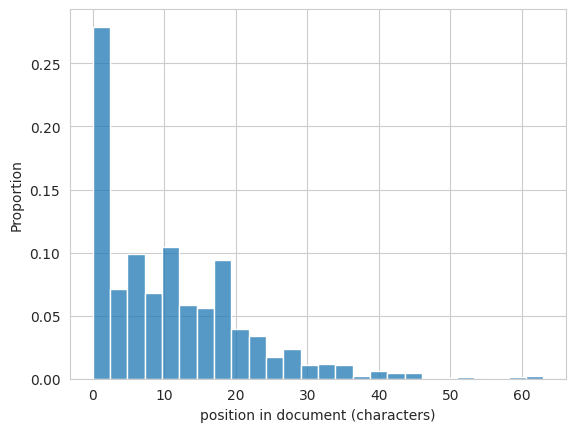

In [5]:
import seaborn as sns

sns.set_style('whitegrid')

fig_df = ret_df.copy()
fig_df['chunk_index'] = (fig_df['chunk.start'] // fig_df['chunk.size'])
fig_df = fig_df.drop_duplicates(['document.pmid', 'chunk_index'])

fig = sns.histplot(fig_df[fig_df['document source'] != 'pubmed'], x='chunk_index', stat='proportion')
fig.set_xlabel('position in document (characters)')


count       569.000000
mean      32295.446397
std       13908.565979
min        1249.000000
25%       23699.000000
50%       31235.000000
75%       39800.000000
max      124069.000000
Name: document_length, dtype: float64

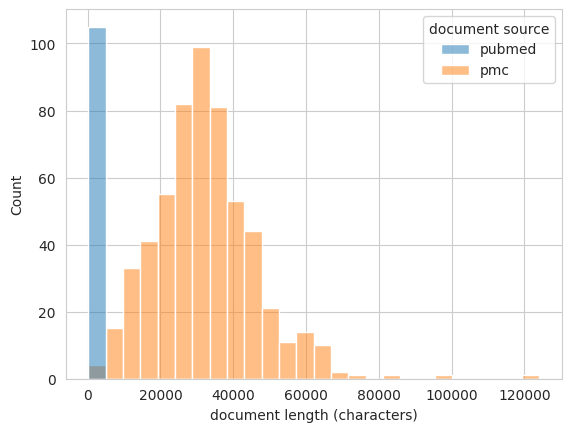

In [6]:
fig_df = doc_df.copy()
# fig_df['document_length'] = fig_df['document_length'] / 1000

fig = sns.histplot(fig_df.drop_duplicates(['document.pmid']), x='document_length', hue='document source')
fig.set_xlabel('document length (characters)')

fig_df[fig_df['document source'] == 'pmc']['document_length'].describe()

Text(0.5, 0, 'number of supporting passages')

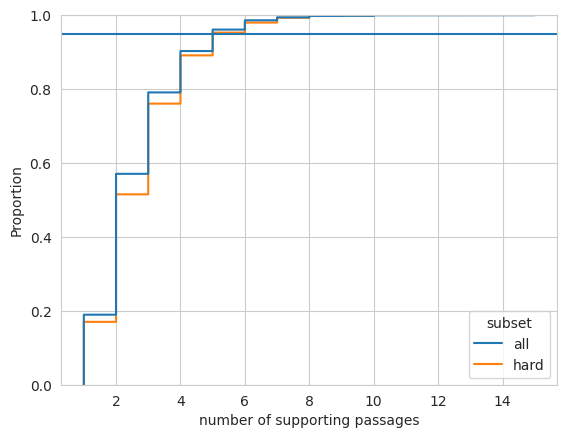

In [7]:
# how many "true" chunks per document per claim
import pandas as pd

ret_counts_df = ret_df.groupby(['document.pmid', 'claim.flat']).agg({'chunk.id': 'nunique'}).reset_index()
ret_counts_df['subset'] = 'all'

hard_df = read_jsonl('../data/civicfact-2026.03.03/filters.hard.jsonl.gz')
hard_df = hard_df.drop_duplicates(['claim.flat', 'document.pmid']).merge(ret_counts_df)
hard_df['subset'] = 'hard'

fig_df = pd.concat([ret_counts_df, hard_df])

fig = sns.ecdfplot(fig_df, x='chunk.id', hue='subset')
fig.axhline(0.95)
fig.set_xlabel('number of supporting passages')